# Visualisation with ggplot2

```{figure} images/ggplot2.png
---
scale: 5%
align: right
---
```

The last tidyverse package we will look at this week is `ggplot2` which is designed to make (tidy) data visualisation more effective. Let's look at a simple scatter plot to get a sense of how `ggplot()` works:


Warning message:
“Removed 2 rows containing missing values or values outside the scale range
(`geom_point()`).”


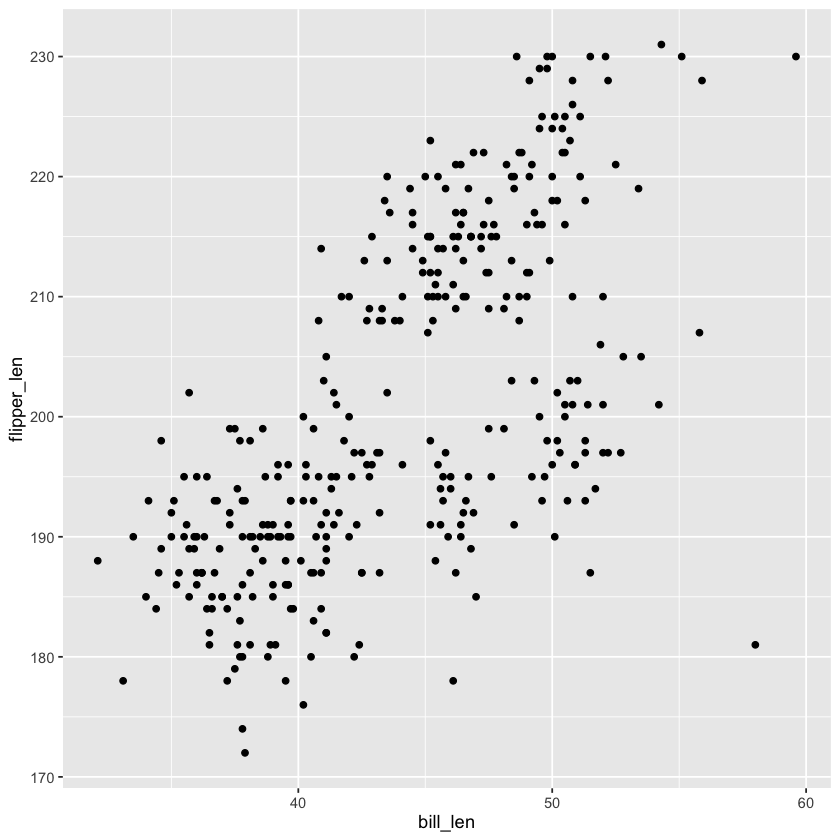

In [13]:
library(ggplot2)

ggplot(penguins,aes(x = bill_len, y = flipper_len)) +
  geom_point()

The `ggplot()` function accepts the data you want to plot as the first argument (in this case `penguins`). The we specify the aesthetics (`aes`) which connect variables in the data to visual properties of the plot. In this case we have specified that we want to map `bill_len` on to the x axis and `flipper_len` on to the y axis. Then we add a geometry, in this case points using `+ geom_point()`.

Note the warning message above, this happened because there are `NA`s in the data. So before we go any further let's deal with those.


In [46]:
clean_penguins <- filter(penguins,
                         !is.na(bill_len),
                         !is.na(flipper_len))

Now let's add some axis labels and colour the points by species of penguin:

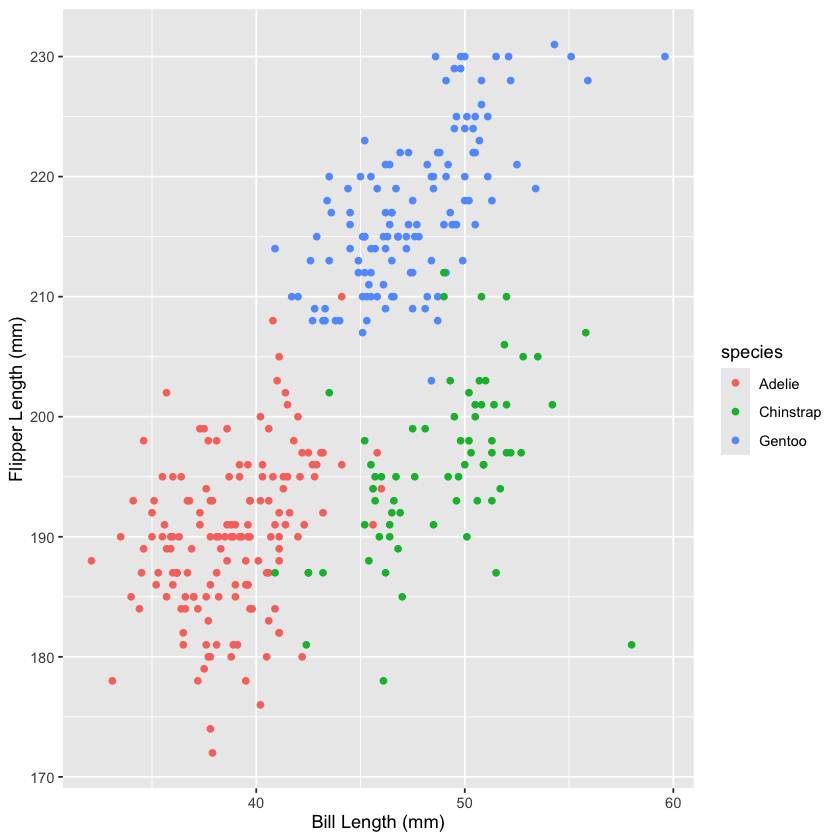

In [47]:
ggplot(clean_penguins,aes(x = bill_len, y = flipper_len, colour = species)) +
  geom_point()+
  xlab("Bill Length (mm)")+
  ylab("Flipper Length (mm)")

This is the same plot as before with a couple of tweaks. We have added `colour` to the aesthetics and mapped it onto the variable `species`. Then we added two additional layers which are the x axis labels and y axis labels. We can improve it further by adding more layers and aesthetics. Let's make it more accessible by using shapes as well as colours. We can also add a trend line for each species.

`geom_smooth()` using formula = 'y ~ x'


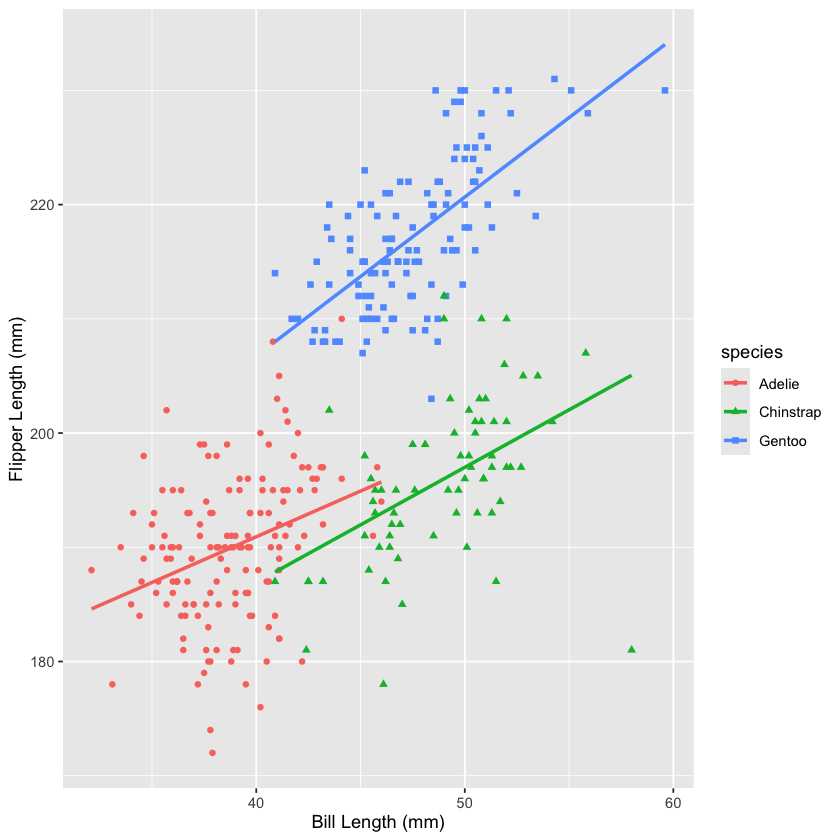

In [48]:
ggplot(clean_penguins,aes(x = bill_len, y = flipper_len, colour = species, shape = species)) +
  geom_point()+
  xlab("Bill Length (mm)")+
  ylab("Flipper Length (mm)")+
  geom_smooth(method = "lm", se = FALSE)

Now we have `shape` mapped on to `species` as well as `colour` and we have added a linear trend line for each group.

## Themes

The colours and fonts used in the plot are the defaults for `ggplot()`, but you can easily try different styles by adding a theme layer:


`geom_smooth()` using formula = 'y ~ x'


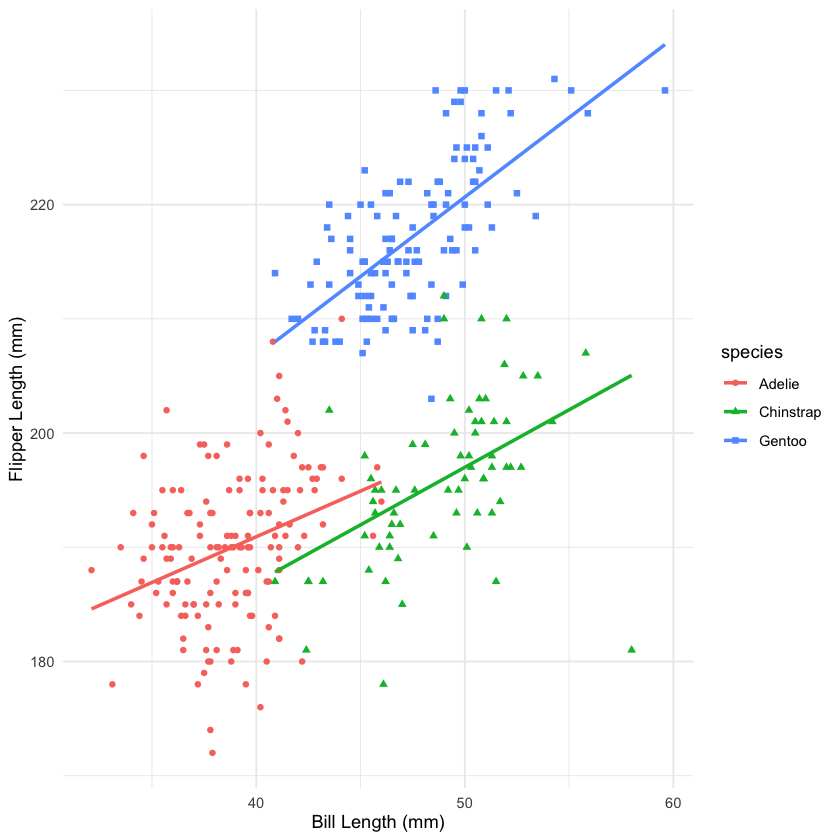

In [49]:
ggplot(clean_penguins,aes(x = bill_len, y = flipper_len, colour = species, shape = species)) +
  geom_point()+
  xlab("Bill Length (mm)")+
  ylab("Flipper Length (mm)")+
  geom_smooth(method = "lm", se = FALSE)+
  theme_minimal()

`theme_minimal()` does what the name suggests. There are other themes available to `ggplot()` and there are packages that provide yet more. You can even make your own bespoke themes. 

## Faceting plots

If you want a multi-panel plot, this is also easily achieved. Let's have a separate scatter plot for each species.

`geom_smooth()` using formula = 'y ~ x'


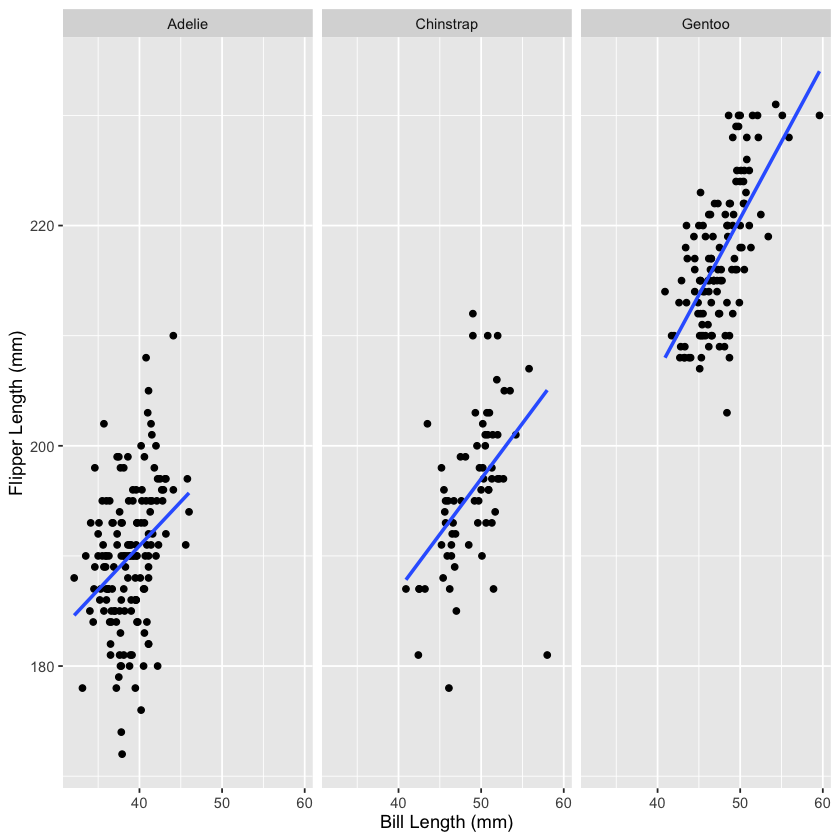

In [50]:
ggplot(clean_penguins,aes(x = bill_len, y = flipper_len)) +
  geom_point()+
  xlab("Bill Length (mm)")+
  ylab("Flipper Length (mm)")+
  geom_smooth(method = "lm", se = FALSE)+
  facet_wrap(~species)

All we have done here is take species out of the aesthetic and given it instead to the `facet_wrap()` layer. This means ggplot will produce as many panels as there are distinct values in the `species` variable. Note that by default, `ggplot()` has given each panel the same scales to facilitate comparison.

## geoms

So far, we have only used the `geom_point()` and `geom_smooth()` geometries, but there are many different geoms to choose from, including:
* `geom_histogram()`
* `geom_boxplot()`
* `geom_line()`


Different geoms will require different mappings in the `aes()`. A histogram only needs a variable to be mapped to the x axis for instance.


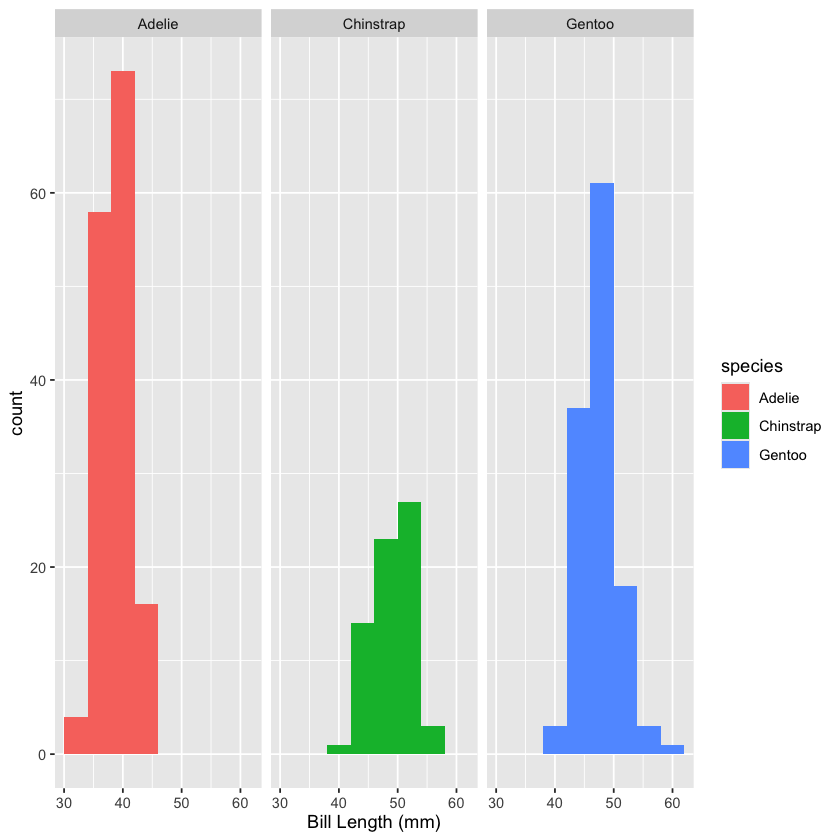

In [52]:
ggplot(clean_penguins,aes(x = bill_len, fill = species)) +
  geom_histogram(binwidth = 4)+
  xlab("Bill Length (mm)")+
  facet_wrap(~species)


The same principles apply whatever the geom you are using. `aes()` supplies the variable : plot mapping, and then we add various layers to get the end result we want. I have used `fill` rather than `colour` here. Although `colour` would have worked fine, it refers to the outline colour, while `fill` refers to the inner colour of a shape. So `fill` tends to work better with a histogram.

## Plotting summary stats

Often we want to plot means and error bars, not just raw data points. There are two main options if that is your objective. You could use `group_by()` and `summarise()` to create your summary statistics and then pass that summary data to `ggplot()`.

Alternatively, there are also some summarising capabilities built in to `ggplot()` if you are working with the raw data. Let's look at `body_mass` per `species` to demonstrate this:


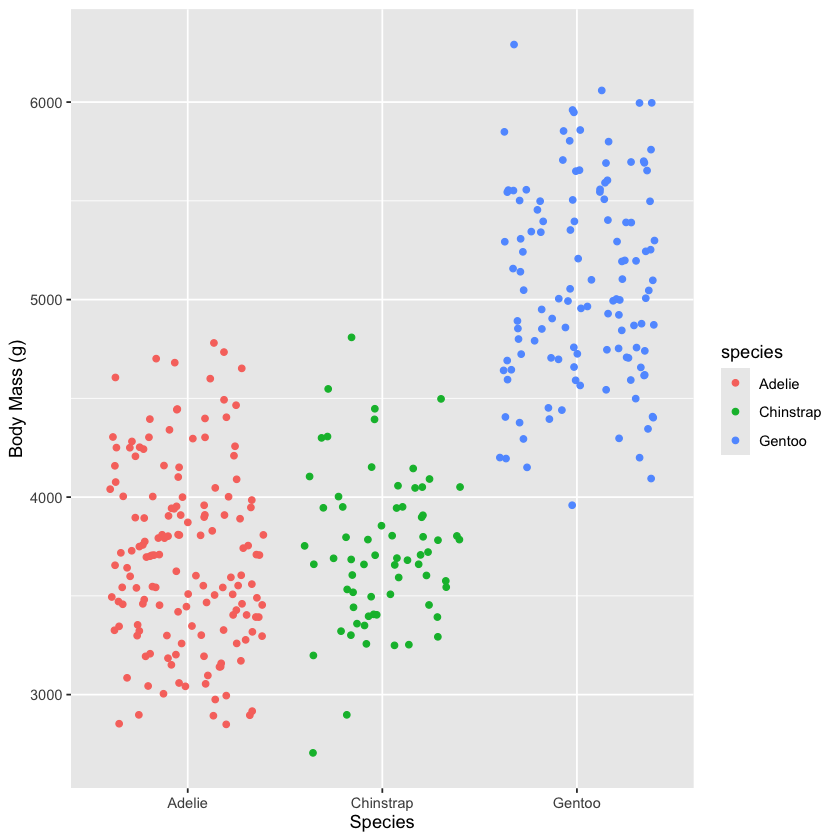

In [31]:
ggplot(clean_penguins,aes(species,body_mass,colour = species))+
  geom_jitter()+
  xlab("Species")+
  ylab("Body Mass (g)")

Here we have created a plot with `species` mapped to the x axis and `body_mass` mapped to the y axis. I have also mapped `species` on to `colour` so that it is clear which species each dot belongs to. I have used the `geom_jitter()` geom, which is the same as `geom_point()` but it has added some random noise to the x position, so that all the data points are not on top of each other. Try running the above code with `geom_point()` instead to see the difference.

Now, if I want to plot a mean data point for each species I can add a `stat_summary()` layer:

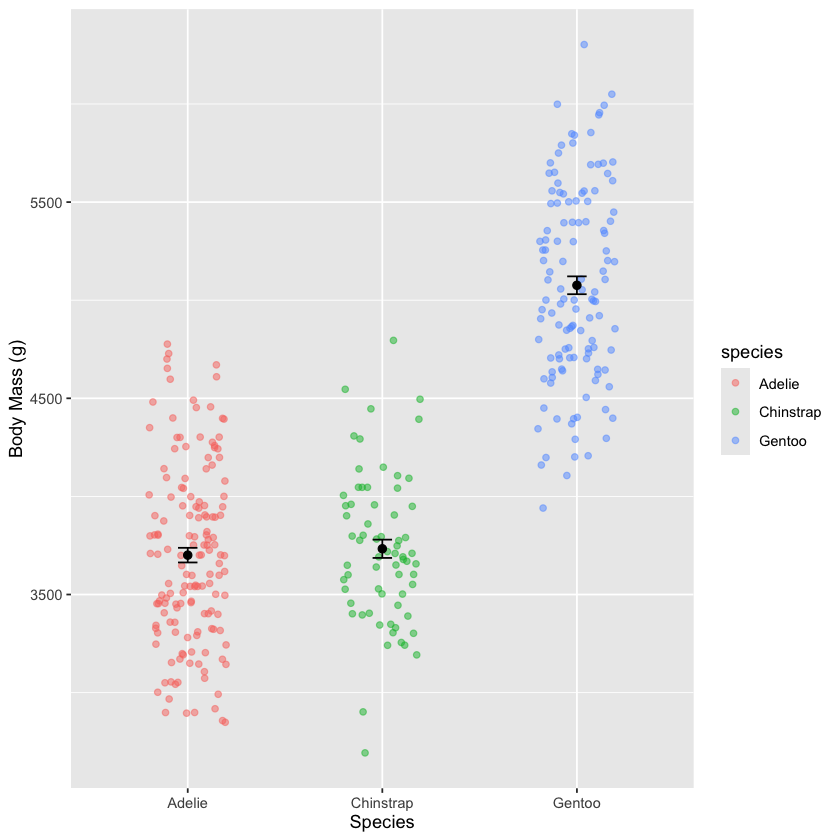

In [43]:
ggplot(clean_penguins,aes(species,body_mass,colour = species))+
  geom_jitter(alpha = 0.5, width = 0.2)+
  xlab("Species")+
  ylab("Body Mass (g)")+
  stat_summary(fun = mean, geom = "point", size = 2, colour = "black", shape = 19)+
  stat_summary(fun.data = mean_se, geom = "errorbar", width = 0.1, colour = "black")

For this plot I have used the `stat_summary()` layers to add a mean data point and error bars showing the standard error (SE). You may have noticed I also added an `alpha` parameter to `geom_jitter()`. This controls the transparency of the points. Making them a bit transparent helps give prominence to the means and it allows us to see where data points overlap. I also set the `width` parameter so that there is a little more space between the clouds of dots.